# Workshop 5 - GAN Evaluation, Failure Modes and Augmentation (Fashion-MNIST, Team 3)

This notebook **runs the full evaluation of the Workshop 5 generators** - Vanilla DCGAN and WGAN-GP - using the artifacts produced by the 100-epoch training runs. It is the analysis companion to `Training_Pipeline.ipynb` and maps directly to the report sections:

- Training dynamics and convergence stability.
- Generation quality: Fréchet Fashion-MNIST Distance (FFD), domain Inception Score, mode coverage and intra-class diversity.
- Qualitative comparison: real vs generated grids.
- Failure mode analysis: mode collapse, discriminator dominance, WGAN-GP loss growth, checkerboard artifacts.
- Downstream data augmentation: three-condition comparison against the real-only baseline.

The notebook is self-contained in the sense that it only needs the repository artifacts already committed under `checkpoints/` and `runs/workshop5/`; it does not retrain the GANs.

## 0. Configuration and environment

In [1]:
import json
import os
import sys
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")
BASE = Path.cwd()
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Image, display

from src.data import CLASS_NAMES
from src.gan import load_generator_checkpoint, pick_device, set_seed
from src.generate_samples import plot_side_by_side_grid, sample_from_generator
from src.train_gan import plot_gan_training_curves

%matplotlib inline

SEED = 42
set_seed(SEED)
device = pick_device("auto")
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | device: {device}")

python 3.12.14 | torch 2.14.0 | device: mps


## 1. Load the reported artifacts

| Artifact | Content |
|---|---|
| `runs/workshop5/vanilla_gan/summary.json` | 100-epoch history: D/G BCE, D accuracy real/fake, D probability |
| `runs/workshop5/wgan_gp/summary.json` | 100-epoch history: critic loss, Wasserstein distance, GP, G loss |
| `runs/workshop5/gan_quality_metrics.json` | FFD, IS, coverage, KL and diversity for 5,000 samples |
| `runs/workshop5/augmentation_results.json` | Three-condition SmallCNN retraining results |
| `runs/workshop5/generated_vanilla.npz`, `generated_wgan_gp.npz` | Cached generated samples used by the report |

In [2]:
RUNS = BASE / "runs" / "workshop5"
van_summary = json.loads((RUNS / "vanilla_gan" / "summary.json").read_text())
wgan_summary = json.loads((RUNS / "wgan_gp" / "summary.json").read_text())
quality = json.loads((RUNS / "gan_quality_metrics.json").read_text())
augmentation = json.loads((RUNS / "augmentation_results.json").read_text())

print(f"vanilla epochs: {van_summary['epochs']} | final D loss: {van_summary['final_metrics']['d_loss']:.3f} | final G loss: {van_summary['final_metrics']['g_loss']:.3f}")
print(f"wgan-gp epochs: {wgan_summary['epochs']} | final Wasserstein: {wgan_summary['final_metrics']['wasserstein_dist']:.3f} | final GP: {wgan_summary['final_metrics']['gp_loss']:.3f}")

vanilla epochs: 100 | final D loss: 0.579 | final G loss: 1.288
wgan-gp epochs: 100 | final Wasserstein: 2.214 | final GP: 0.258


## 2. Training dynamics and convergence stability

The two signatures are qualitatively different:

- **Vanilla GAN:** the BCE game settles into a stable but biased equilibrium. Discriminator accuracy stabilizes around 60% on real and 80% on fake, clearly off the 50% Nash point; label smoothing 0.9 keeps the discriminator from becoming overconfident.
- **WGAN-GP:** the Wasserstein estimate rises briefly while the critic learns, then decreases monotonically. The gradient penalty shrinks toward zero, and the raw generator loss grows because the critic scores real images ever higher - not because the generator is degrading.

The cell reproduces the three-panel figure used in the report.

[train_gan] saved training stability comparison curves -> /Users/jhojan/Documents/Universidad/Semestre10/MachineLearning/Workshops/MachineLearning-w5/Workshop_5/runs/workshop5/gan_training_curves_reproduced.png


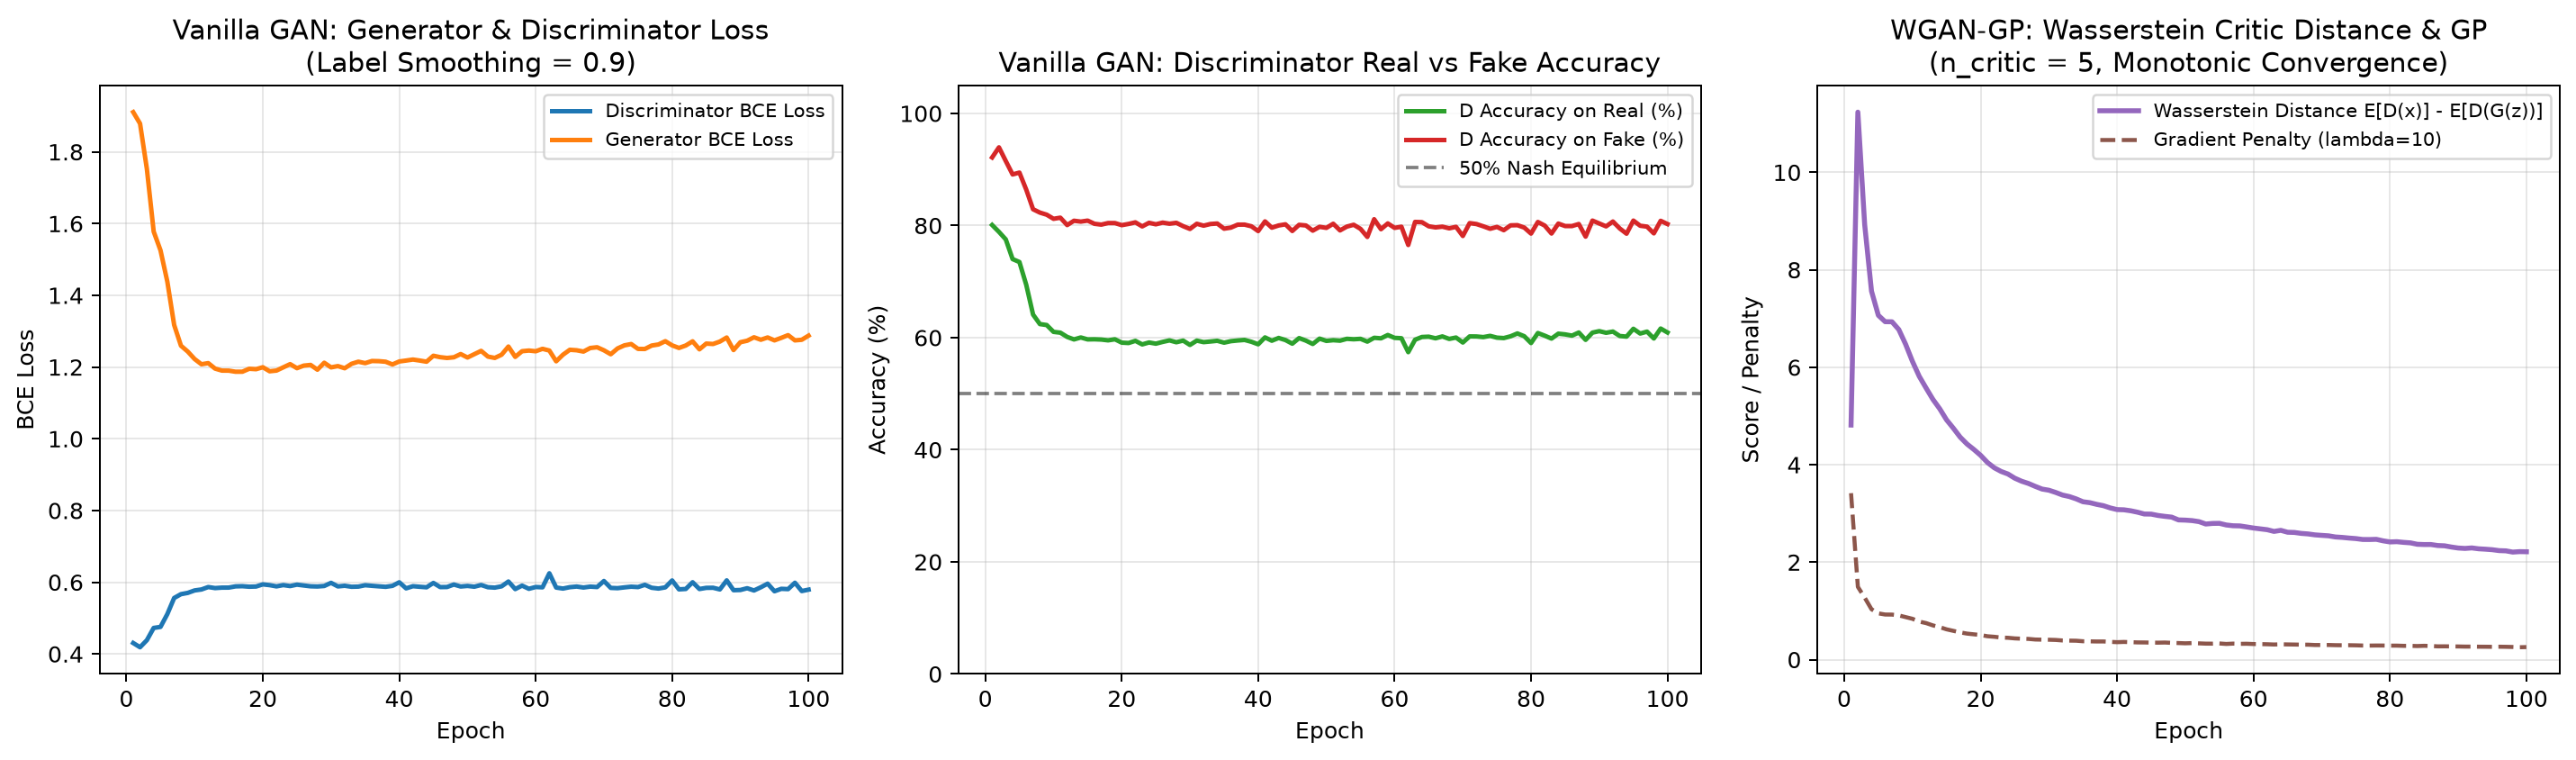

In [3]:
curve_path = RUNS / "gan_training_curves_reproduced.png"
plot_gan_training_curves(van_summary, wgan_summary, curve_path)
display(Image(filename=str(curve_path)))

## 3. Generation quality - the report table

The reference row is the real test split; its FFD is zero by construction. The two generators are evaluated on 5,000 samples each with the frozen Workshop 2 `SmallCNN` as feature extractor and classifier.

In [4]:
def row(name, m):
    return (
        f"{name:<14} {m['frechet_distance']:>8.3f} "
        f"{m['inception_score_mean']:>8.3f} +/- {m['inception_score_std']:.3f} "
        f"{m['mean_confidence']:>9.3f} {m['covered_modes_gt_2pct']:>5}/10 "
        f"{m['kl_to_uniform']:>10.4f} {m['intra_class_l2_diversity']:>10.3f}"
    )

print(f"{'model':<14} {'FFD':>8} {'IS':>16} {'confidence':>9} {'modes':>7} {'KL_unif':>10} {'L2_div':>10}")
print(row("Real test", quality["real_test_reference"]))
print(row("Vanilla GAN", quality["vanilla_gan"]))
print(row("WGAN-GP", quality["wgan_gp"]))

model               FFD               IS confidence   modes    KL_unif     L2_div
Real test         0.000    8.327 +/- 0.097     0.933    10/10     0.0002      8.842
Vanilla GAN       1.560    6.711 +/- 0.131     0.852    10/10     0.0135      8.751
WGAN-GP           5.166    6.127 +/- 0.091     0.824    10/10     0.0207      8.528


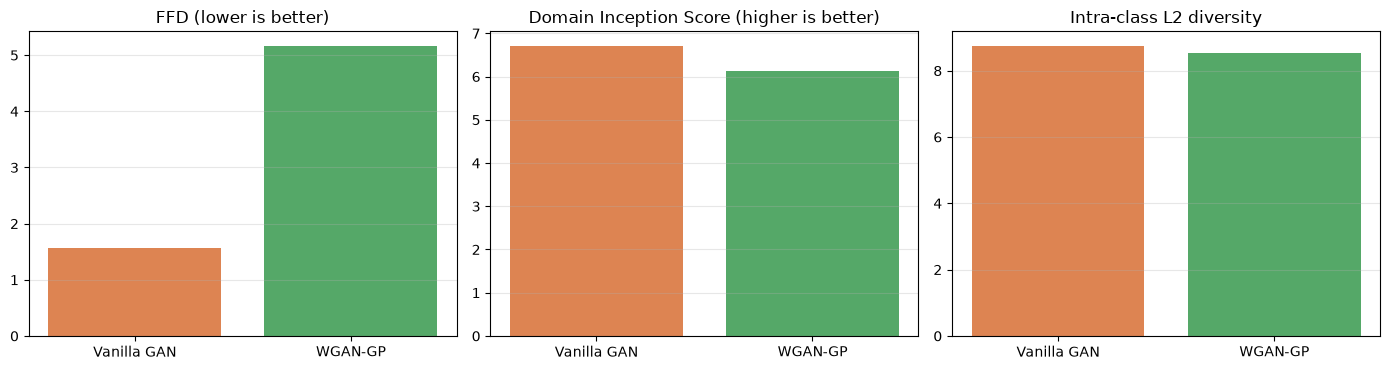

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
models = ["Vanilla GAN", "WGAN-GP"]
keys = ["vanilla_gan", "wgan_gp"]
colors = ["#dd8452", "#55a868"]

axes[0].bar(models, [quality[k]["frechet_distance"] for k in keys], color=colors)
axes[0].set_title("FFD (lower is better)")
axes[1].bar(models, [quality[k]["inception_score_mean"] for k in keys], color=colors)
axes[1].set_title("Domain Inception Score (higher is better)")
axes[2].bar(models, [quality[k]["intra_class_l2_diversity"] for k in keys], color=colors)
axes[2].set_title("Intra-class L2 diversity")
for ax in axes:
    ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

## 4. Qualitative comparison - real vs generated grids

The 8x8 grids use the same random draw for both models and place the real test images first. The comparison is deliberately side by side: silhouettes, textures and failure patterns are easier to judge when the three distributions share a layout.

cached samples: vanilla=(5000, 28, 28) | wgan-gp=(5000, 28, 28)


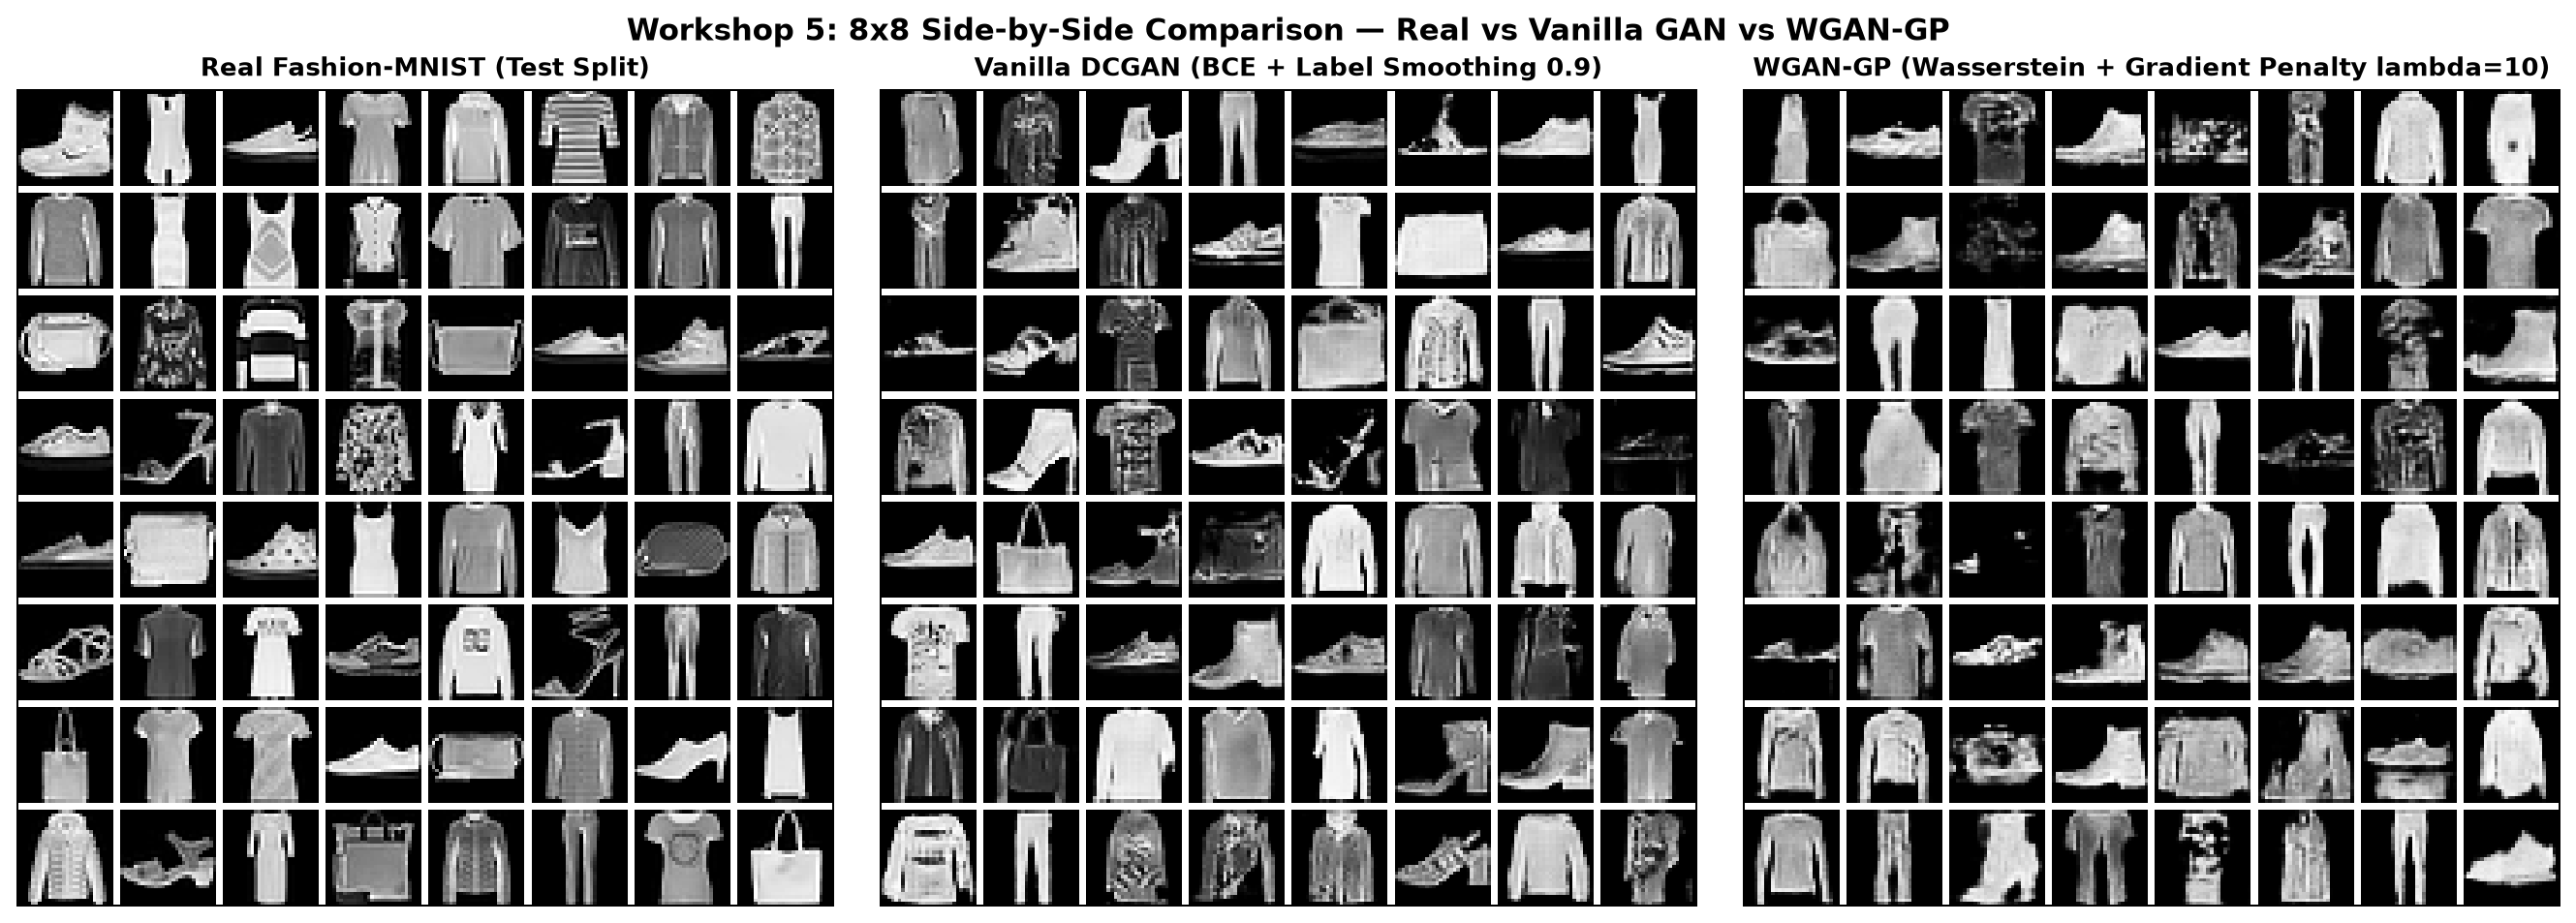

In [6]:
# Load the cached generated samples (5,000 each) and the 8x8 report grid.
van_samples = np.load(RUNS / "generated_vanilla.npz")["images"]
wgan_samples = np.load(RUNS / "generated_wgan_gp.npz")["images"]
print(f"cached samples: vanilla={van_samples.shape} | wgan-gp={wgan_samples.shape}")
display(Image(filename=str(RUNS / "sample_grid_8x8.png")))

[data] reusing cached split from /Users/jhojan/Documents/Universidad/Semestre10/MachineLearning/Workshops/MachineLearning-w5/Workshop_2/data/splits.json
[generate_samples] saved 4x4 grid -> /Users/jhojan/Documents/Universidad/Semestre10/MachineLearning/Workshops/MachineLearning-w5/Workshop_5/runs/workshop5/sample_grid_4x4_reproduced.png


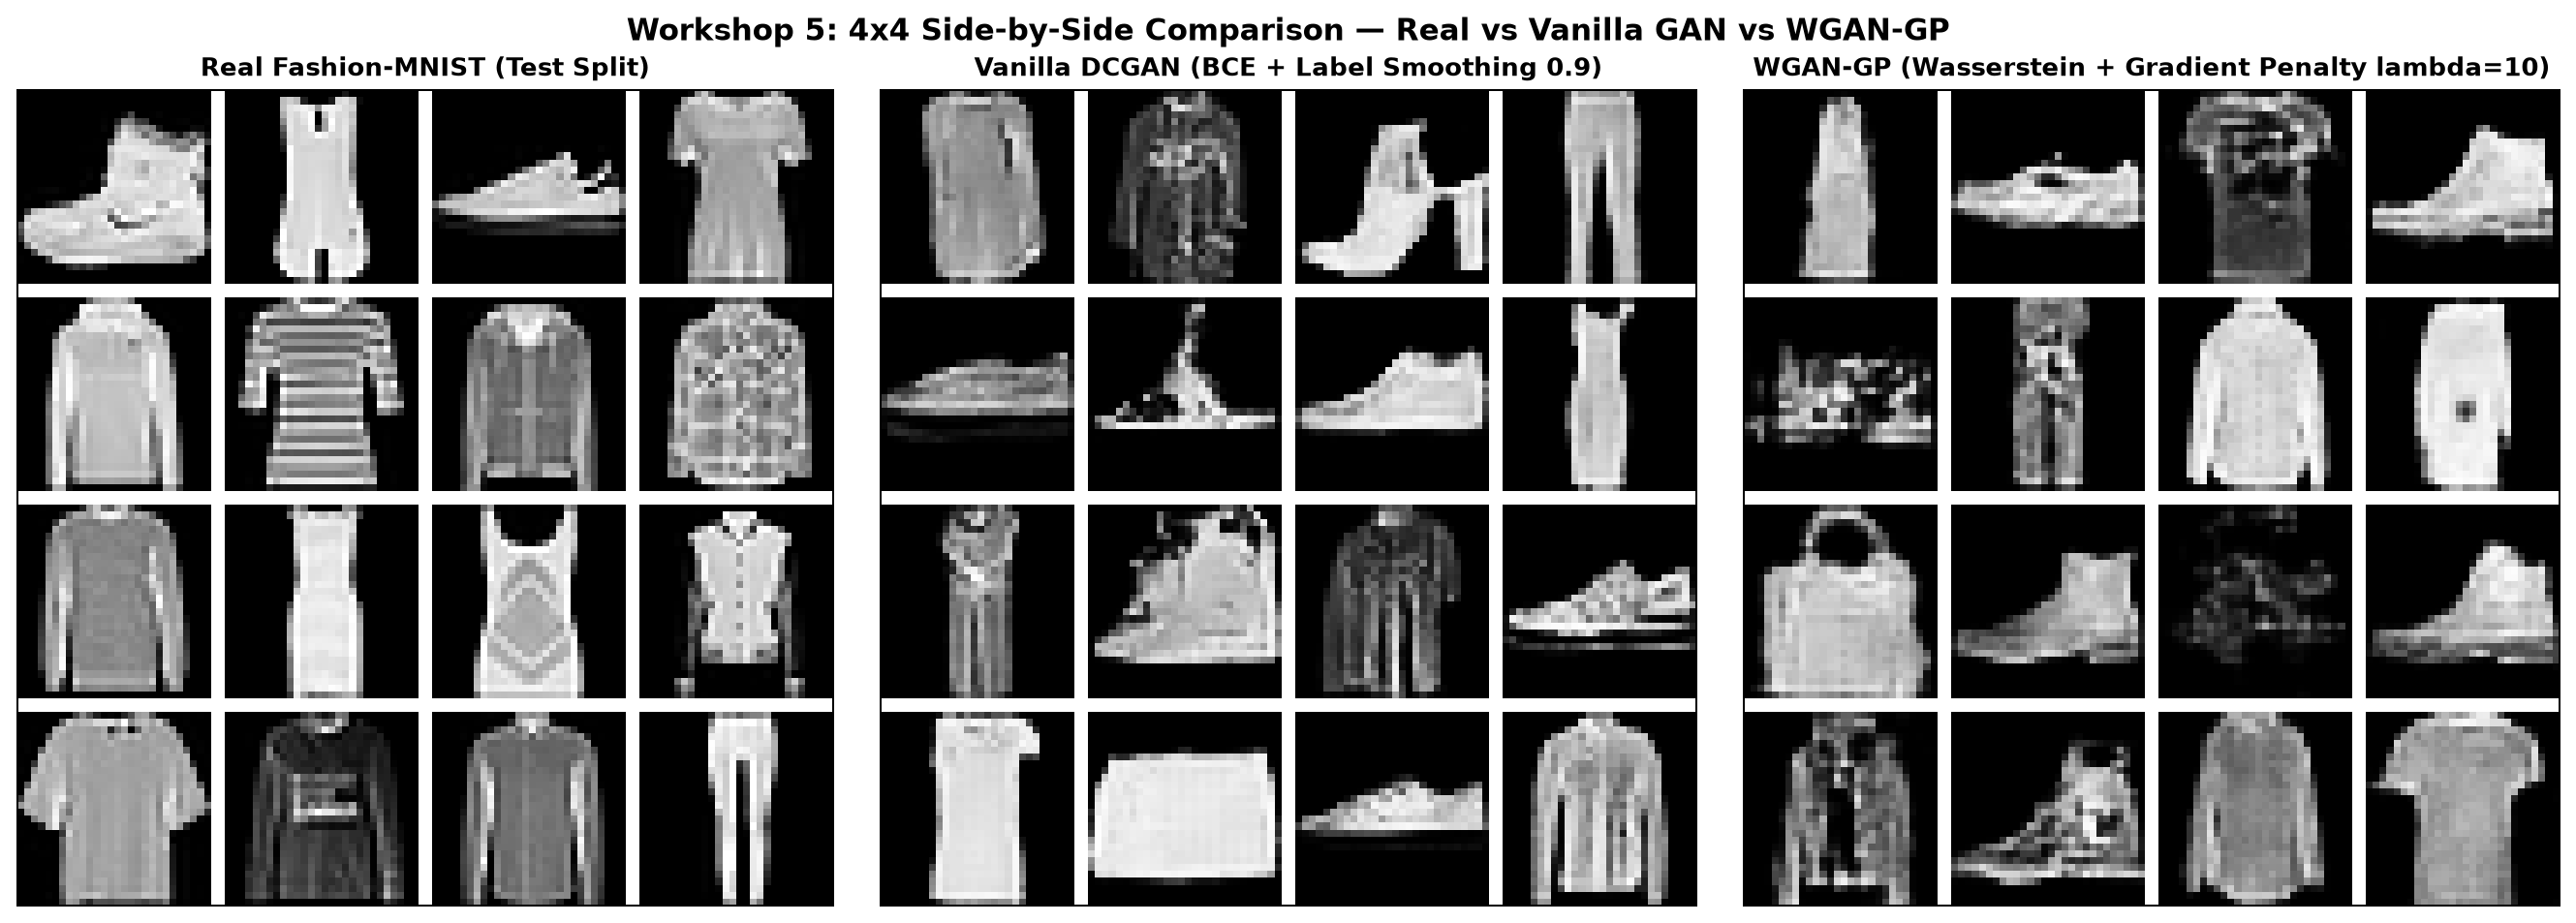

In [7]:
# Reproduce the 4x4 side-by-side grid from the cached samples and the real test split.
from src.data import get_full_dataset, get_splits

images, labels = get_full_dataset()
splits = get_splits(labels, seed=SEED)
real_test = images[np.asarray(splits["test"])].astype(np.float32) / 255.0
grid_path = RUNS / "sample_grid_4x4_reproduced.png"
plot_side_by_side_grid(real_test, van_samples, wgan_samples, grid_size=4, out_path=grid_path)
display(Image(filename=str(grid_path)))

## 5. Failure mode analysis

The workshop guide names four canonical pathologies. The cells below check each one against the logged evidence.

### 5.1 Mode collapse - did not occur

Symptom: all generated samples converge to a few near-identical outputs and the class histogram concentrates on few modes. Evidence against it: all 10 classes receive generated mass, the KL to uniform stays around 0.01-0.02 nats, and intra-class diversity is within 1-4% of the real reference.

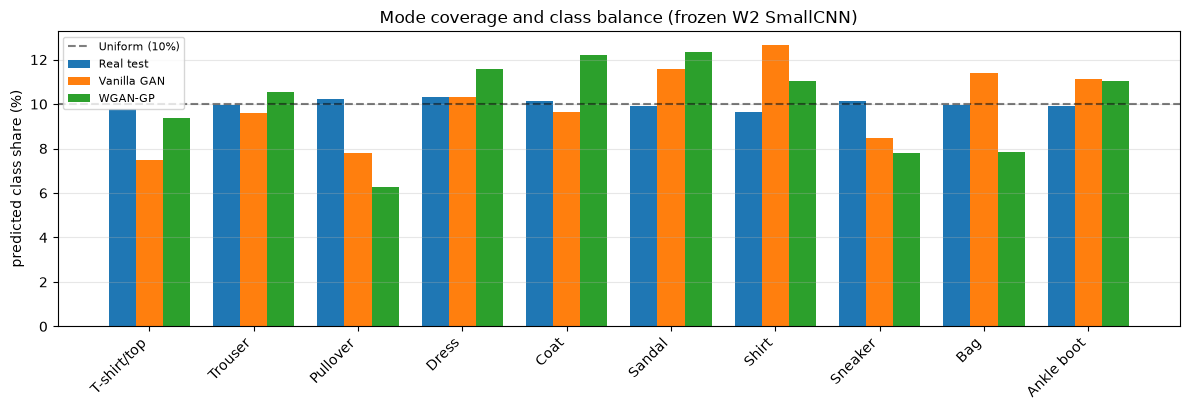

Vanilla GAN  min=7.5% max=12.6% ratio=1.69 modes>2%=10/10
WGAN-GP      min=6.3% max=12.3% ratio=1.97 modes>2%=10/10


In [8]:
fig, ax = plt.subplots(figsize=(12, 4.2))
x = np.arange(len(CLASS_NAMES))
width = 0.26
for offset, key, label in [(-width, "real_test_reference", "Real test"), (0, "vanilla_gan", "Vanilla GAN"), (width, "wgan_gp", "WGAN-GP")]:
    freq = quality[key]["class_frequencies"]
    ax.bar(x + offset, [freq[c] * 100 for c in CLASS_NAMES], width=width, label=label)
ax.axhline(10, color="black", linestyle="--", alpha=0.5, label="Uniform (10%)")
ax.set_xticks(x)
ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_ylabel("predicted class share (%)")
ax.set_title("Mode coverage and class balance (frozen W2 SmallCNN)")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

for key, label in [("vanilla_gan", "Vanilla GAN"), ("wgan_gp", "WGAN-GP")]:
    freq = np.array([quality[key]["class_frequencies"][c] for c in CLASS_NAMES])
    print(f"{label:<12} min={freq.min()*100:.1f}% max={freq.max()*100:.1f}% ratio={freq.max()/freq.min():.2f} modes>2%={quality[key]['covered_modes_gt_2pct']}/10")

### 5.2 Discriminator dominance - contained by label smoothing

The vanilla discriminator stabilizes at roughly 60% accuracy on real and 80% on fake, better than the 50% Nash point. The one-sided label smoothing (real target 0.9) is the mitigation: the discriminator never sees hard targets, its mean probability on real data stays around 0.66, and the generator loss plateaus instead of exploding.

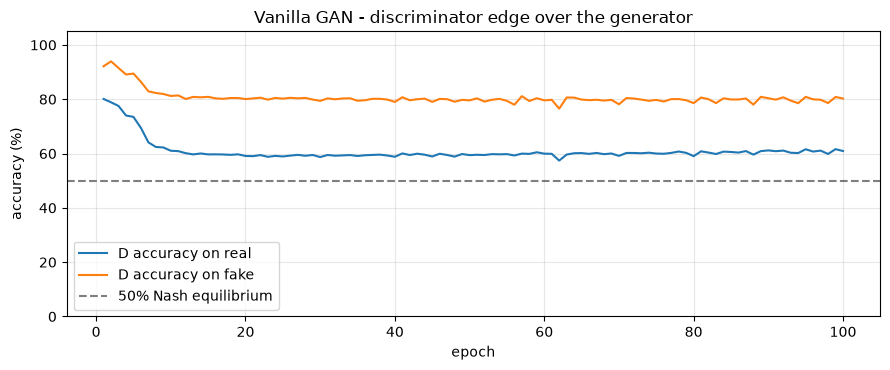

final D accuracy: real=60.9% fake=80.3% | mean D prob on real=0.554


In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
epochs = [r["epoch"] for r in van_summary["history"]]
ax.plot(epochs, [r["d_acc_real"] * 100 for r in van_summary["history"]], label="D accuracy on real")
ax.plot(epochs, [r["d_acc_fake"] * 100 for r in van_summary["history"]], label="D accuracy on fake")
ax.axhline(50, color="black", linestyle="--", alpha=0.5, label="50% Nash equilibrium")
ax.set_xlabel("epoch")
ax.set_ylabel("accuracy (%)")
ax.set_title("Vanilla GAN - discriminator edge over the generator")
ax.set_ylim(0, 105)
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

final = van_summary["final_metrics"]
print(f"final D accuracy: real={final['d_acc_real']*100:.1f}% fake={final['d_acc_fake']*100:.1f}% | mean D prob on real={final['d_prob_real']:.3f}")

### 5.3 WGAN-GP generator loss growth - an expected signal

The raw generator objective `-E[C(G(z))]` rises from about 4 to 23 while sample quality improves. This is expected: the critic becomes sharper and scores real images higher, so the generator's negative score grows even as its samples get better. The informative curves are the **Wasserstein distance** (falls monotonically toward 2.2) and the **gradient penalty** (decays toward 0.26), both shown below.

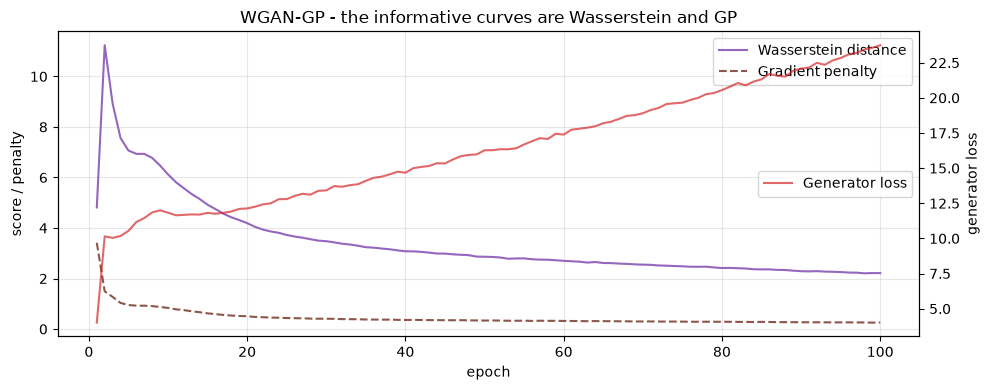

In [10]:
fig, ax1 = plt.subplots(figsize=(10, 4.0))
epochs = [r["epoch"] for r in wgan_summary["history"]]
ax1.plot(epochs, [r["wasserstein_dist"] for r in wgan_summary["history"]], color="#9467bd", label="Wasserstein distance")
ax1.plot(epochs, [r["gp_loss"] for r in wgan_summary["history"]], color="#8c564b", linestyle="--", label="Gradient penalty")
ax1.set_xlabel("epoch")
ax1.set_ylabel("score / penalty")
ax1.grid(alpha=0.3)
ax1.legend(loc="upper right")

ax2 = ax1.twinx()
ax2.plot(epochs, [r["g_loss"] for r in wgan_summary["history"]], color="#d62728", alpha=0.7, label="Generator loss")
ax2.set_ylabel("generator loss")
ax2.legend(loc="center right")
ax1.set_title("WGAN-GP - the informative curves are Wasserstein and GP")
fig.tight_layout()
plt.show()

### 5.4 Checkerboard artifacts - transient

Epoch-10 grids show faint checkerboard structure, the classic aliasing artifact of stride-2 transposed convolutions. It fades over training and is largely absent from the epoch-100 samples; the terminal `3 x 3` stride-1 convolution is the architectural mitigation already in place.

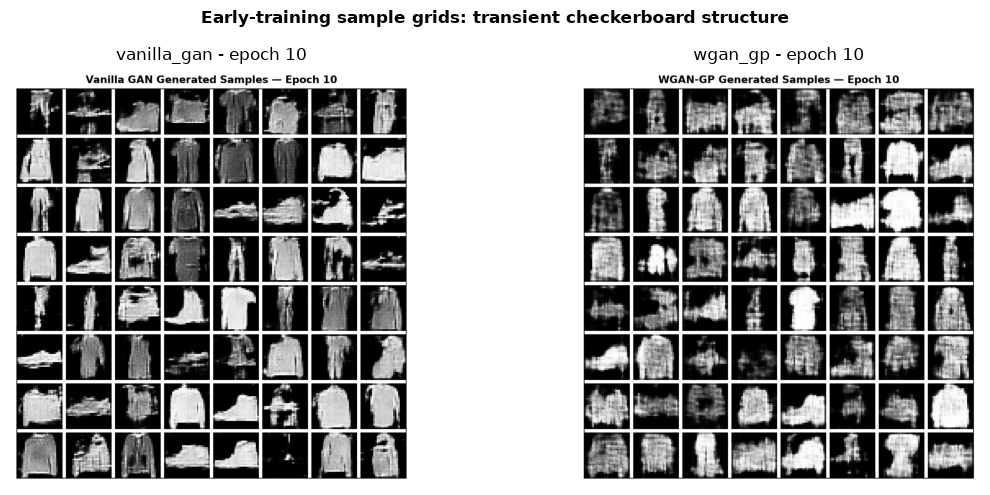

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.0))
for ax, path in zip(axes, [RUNS / "vanilla_gan" / "samples" / "samples_epoch_010.png", RUNS / "wgan_gp" / "samples" / "samples_epoch_010.png"]):
    ax.imshow(plt.imread(path))
    ax.set_title(path.parent.parent.name + " - epoch 10")
    ax.axis("off")
fig.suptitle("Early-training sample grids: transient checkerboard structure", fontweight="bold")
fig.tight_layout()
plt.show()

## 6. Latent-space interpolation (optional qualitative check)

A healthy generator maps nearby noise vectors to similar images. Interpolating linearly between two random `z` vectors and decoding the path is a quick way to inspect whether the generator has learned a smooth latent space rather than memorized isolated samples.

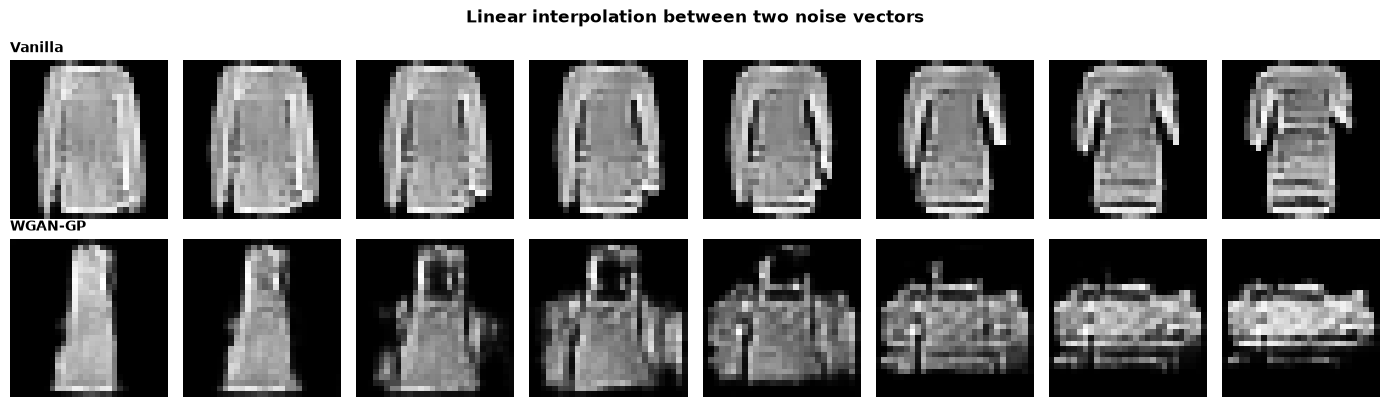

In [12]:
def interpolation_panel(gen, steps=8, seed=0):
    g = torch.Generator().manual_seed(seed)
    z1 = torch.randn(1, gen.z_dim, generator=g)
    z2 = torch.randn(1, gen.z_dim, generator=g)
    alphas = torch.linspace(0, 1, steps).unsqueeze(1)
    z = (1 - alphas) * z1 + alphas * z2
    gen = gen.to(device).eval()
    with torch.no_grad():
        out = gen(z.to(device)).cpu().numpy()[:, 0]
    return np.clip((out + 1) / 2, 0, 1)

gen_van, _ = load_generator_checkpoint(BASE / "checkpoints" / "gan_vanilla_best.pt", map_location="cpu")
gen_wgan, _ = load_generator_checkpoint(BASE / "checkpoints" / "gan_wgan_best.pt", map_location="cpu")

fig, axes = plt.subplots(2, 8, figsize=(14, 4.2))
for row, (name, gen) in enumerate([("Vanilla", gen_van), ("WGAN-GP", gen_wgan)]):
    imgs = interpolation_panel(gen, steps=8, seed=SEED + row)
    for col, ax in enumerate(axes[row]):
        ax.imshow(imgs[col], cmap="gray")
        ax.axis("off")
    axes[row][0].set_title(name, loc="left", fontsize=10, fontweight="bold")
fig.suptitle("Linear interpolation between two noise vectors", fontweight="bold")
fig.tight_layout()
plt.show()

## 7. Downstream augmentation experiment

The table follows the report: each condition retrains the Workshop 2 `SmallCNN` from scratch with the same architecture, optimizer, 25-epoch budget, seed and split. The only difference is the training set: 49,000 real images, or 49,000 real + 3,000 filtered synthetic images.

In [13]:
conditions = augmentation["conditions"]
print(f"{'condition':<26} {'accuracy':>9} {'macro F1':>9} {'ROC-AUC':>8} {'Shirt F1':>9}")
for name, values in conditions.items():
    print(f"{name:<26} {values['accuracy']*100:>8.2f}% {values['f1_macro']:>9.4f} {values['roc_auc_ovr']:>8.4f} {values['per_class_f1']['Shirt']:>9.4f}")

base = conditions["real_only"]
print("\ndelta vs real-only (accuracy / macro F1):")
for name in ["real_plus_vanilla_gan", "real_plus_wgan_gp"]:
    delta_acc = (conditions[name]["accuracy"] - base["accuracy"]) * 100
    delta_f1 = conditions[name]["f1_macro"] - base["f1_macro"]
    print(f"  {name:<24} {delta_acc:+.2f} pts / {delta_f1:+.4f}")

condition                   accuracy  macro F1  ROC-AUC  Shirt F1
real_only                     91.97%    0.9196   0.9953    0.7603
real_plus_vanilla_gan         92.29%    0.9225   0.9954    0.7673
real_plus_wgan_gp             92.25%    0.9224   0.9955    0.7650

delta vs real-only (accuracy / macro F1):
  real_plus_vanilla_gan    +0.31 pts / +0.0029
  real_plus_wgan_gp        +0.28 pts / +0.0028


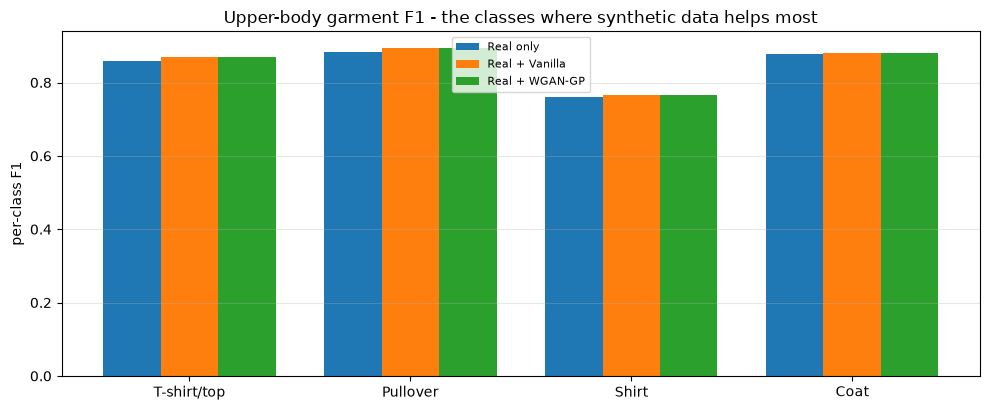

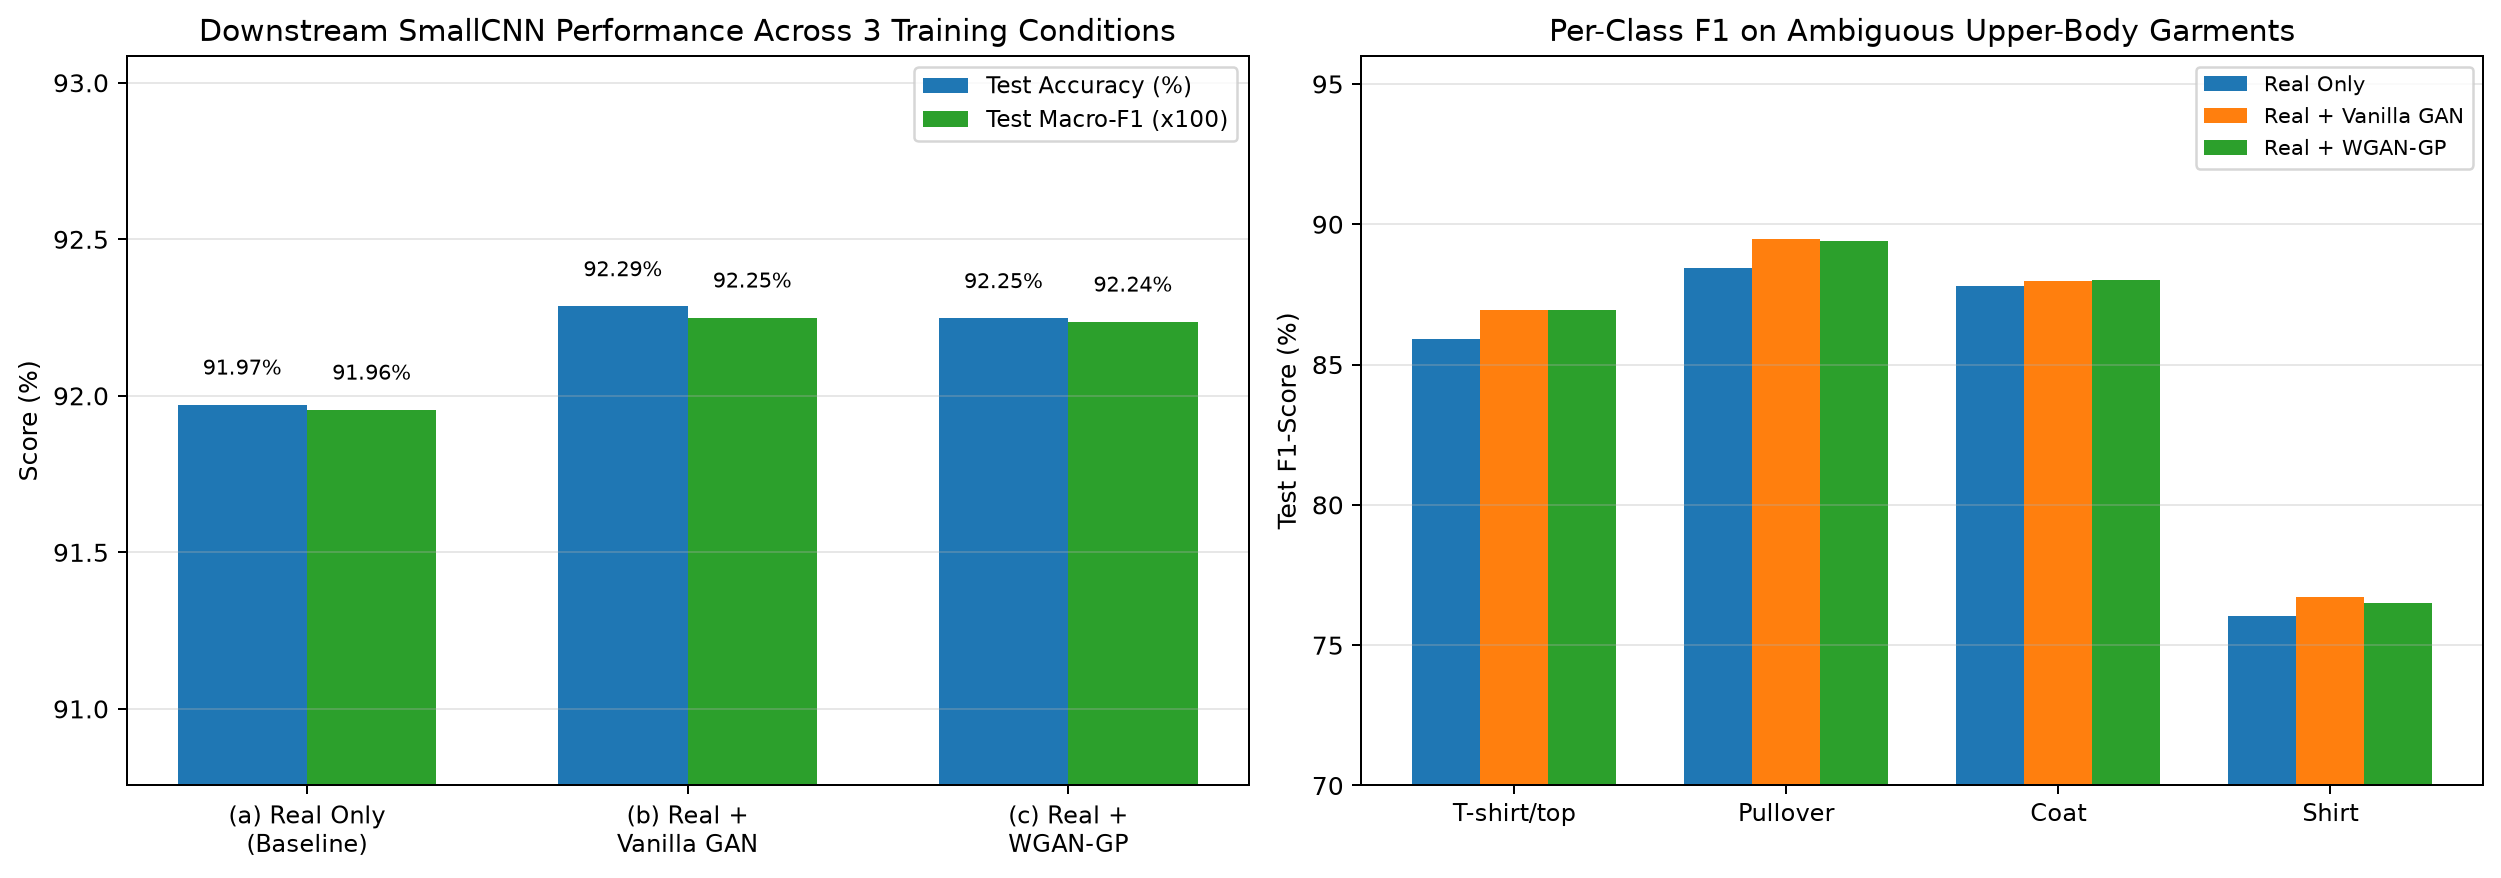

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.2))
classes = ["T-shirt/top", "Pullover", "Shirt", "Coat"]
x = np.arange(len(classes))
width = 0.26
for offset, name, label in [(-width, "real_only", "Real only"), (0, "real_plus_vanilla_gan", "Real + Vanilla"), (width, "real_plus_wgan_gp", "Real + WGAN-GP")]:
    values = [conditions[name]["per_class_f1"][c] for c in classes]
    ax.bar(x + offset, values, width=width, label=label)
ax.set_xticks(x)
ax.set_xticklabels(classes)
ax.set_ylabel("per-class F1")
ax.set_title("Upper-body garment F1 - the classes where synthetic data helps most")
ax.legend(fontsize=8)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()
display(Image(filename=str(RUNS / "augmentation_comparison.png")))

## 8. Reading the results

- The Vanilla GAN is the better generator by every headline metric: FFD 1.56 vs 5.17, domain IS 6.71 vs 6.13, higher teacher acceptance (64.4% vs 58.6%) and slightly higher intra-class diversity.
- Neither model collapses: both cover 10/10 modes with near-uniform class mass and diversity within a few percent of real data.
- WGAN-GP is not a free upgrade at this budget. The Wasserstein objective delivers a more interpretable training signal (monotonic distance, shrinking GP), but the BCE game with one-sided label smoothing produced better samples in 100 epochs.
- GAN augmentation helps modestly and consistently: +0.32 accuracy points with vanilla samples and +0.28 with WGAN-GP, concentrated on the ambiguous upper-body classes. With 49,000 real images the classifier is data-rich, so the ceiling is low; the technique should matter more in a data-scarce regime.
- The honest conclusion is the one in the report: stable training and final sample quality are different axes, and GAN losses alone must never be used as a quality metric.

## 9. Reproducing the evaluation

```bash
# Regenerate 5,000 samples and the 4x4 / 8x8 grids
python -m src.generate_samples --vanilla-ckpt checkpoints/gan_vanilla_best.pt \
    --wgan-ckpt checkpoints/gan_wgan_best.pt --num-samples 5000

# Recompute FFD, domain IS, mode coverage, KL and diversity
python -m src.evaluate_gan --vanilla-ckpt checkpoints/gan_vanilla_best.pt \
    --wgan-ckpt checkpoints/gan_wgan_best.pt --w2-ckpt ../Workshop_2/checkpoints/model_best.pt

# Reproduce the three-condition augmentation experiment
python -m src.augment_and_retrain --vanilla-ckpt checkpoints/gan_vanilla_best.pt \
    --wgan-ckpt checkpoints/gan_wgan_best.pt --num-synthetic 3000 --epochs 25
```

**Note on exact numbers:** the generator RNG stream depends on the accelerator (MPS vs DirectML vs CPU), so a fresh 5,000-sample evaluation can differ slightly from the committed JSON. The ranking (Vanilla > WGAN-GP on FFD and IS) is stable and is the result that matters.